# LightGBM — Previsão do IPCA com variáveis externas defasadas

**Projeto:** IPCA sob pressão externa — análise comparativa entre ARIMAX, Prophet e LightGBM
**Autor:** Gabriel Abreu
**Orientadora:** Bruna Nogueira Rezende

## Fundamentação do modelo

O LightGBM (Ke et al., 2017) é um algoritmo de **gradient boosting baseado em
árvores de decisão**, otimizado por crescimento leaf-wise e histograma de features.
Representa a classe de **modelos não lineares baseados em árvores**:

- Captura **relações não lineares** entre preditores e alvo sem especificação prévia
  da forma funcional (vantagem sobre ARIMAX em regimes com mudanças estruturais).
- Detecta **interações entre features** automaticamente — relevante para o IPCA, onde
  o efeito do câmbio depende da fase do ciclo inflacionário.
- **Não possui estrutura temporal nativa**: a dimensão temporal deve ser explicitamente
  representada na matriz de features.

**Implicação metodológica (limitação reconhecida):** o LightGBM recebe uma matriz
de features mais rica que o ARIMAX e o Prophet (lags adicionais, médias móveis,
variáveis cíclicas). Isso reflete a tradução do mesmo conjunto informacional para a
estrutura nativa do modelo, mas pode gerar vantagem metodológica. Para mitigar esse
viés, o modelo `M0_baseline` é estimado apenas com câmbio e CPI defasados (mesmas
variáveis do ARIMAX e Prophet), permitindo isolar o ganho atribuível à engenharia
de features vs. à arquitetura do algoritmo.

## Estrutura

1. Carregamento e EDA suplementar
2. Transformações e revisão
3. Engenharia de features e prevenção de leakage
4. Estrutura de validação temporal (blocked CV + expanding window)
5. Otimização de hiperparâmetros
6. Avaliação fora da amostra (expanding window, h=1,2,3)
7. Métricas e subperíodos
8. Importância de variáveis
9. Regime de volatilidade (H2)
10. Diebold-Mariano (H3)
11. Visualizações e exportação


## 0. Dependências

In [2]:
pip install lightgbm

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.6/1.6 MB 6.9 MB/s eta 0:00:00a 0:00:01
Note: you may need to restart the kernel to use updated packages.


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import warnings
warnings.filterwarnings('ignore')

import pickle

import lightgbm as lgb
from sklearn.model_selection import ParameterGrid
from sklearn.metrics         import mean_absolute_error, mean_squared_error
from scipy                    import stats

np.random.seed(42)
plt.rcParams['figure.dpi']        = 130
plt.rcParams['axes.spines.top']   = False
plt.rcParams['axes.spines.right'] = False

print(f'LightGBM version: {lgb.__version__}')

LightGBM version: 4.6.0


## 1. Carregamento e EDA suplementar

A análise exploratória completa (gráficos temporais, estatísticas descritivas,
eventos macroeconômicos) está em `01_arimax.ipynb`. Aqui revisamos apenas o que é
diretamente relevante para a engenharia de features do LightGBM.


In [5]:
df_raw = pd.read_csv('../final_df_with_lags.csv', parse_dates=['data'], index_col='data')
df_raw = df_raw.asfreq('MS')

print(f'Shape: {df_raw.shape}')
print(f'Período: {df_raw.index[0].date()} → {df_raw.index[-1].date()}')
print(f'Colunas: {df_raw.columns.tolist()}')
df_raw.head()

Shape: (295, 6)
Período: 2000-06-01 → 2024-12-01
Colunas: ['ipca_pct', 'us_cpi_pct', 'usd_brl_pct', 'us_cpi_lag2', 'us_cpi_lag3', 'usd_brl_lag4']


,ipca_pct,us_cpi_pct,usd_brl_pct,us_cpi_lag2,us_cpi_lag3,usd_brl_lag4
data,,,,,,
2000-06-01,0.23,0.524781,-1.456258,0.058411,0.824499,-1.880826
2000-07-01,1.61,0.232019,-1.400000,0.116754,0.058411,-1.198756
2000-08-01,1.31,0.000000,2.738337,0.524781,0.116754,3.399531
2000-09-01,0.23,0.520833,1.113305,0.232019,0.524781,1.101456
2000-10-01,0.14,0.172712,3.541791,0.000000,0.232019,-1.456258


In [6]:
# Estatísticas suplementares: sazonalidade do IPCA por mês
ipca_by_month = df_raw.groupby(df_raw.index.month)['ipca_pct'].agg(['mean', 'std'])
ipca_by_month.index.name = 'mes'
print('IPCA — média e desvio por mês do ano (treino + teste):')
print(ipca_by_month.round(4).to_string())

print('''
→ Padrão sazonal claro: meses do início do ano (jan, fev) e início do segundo semestre
  apresentam médias mais elevadas. Justifica a inclusão de variáveis cíclicas
  (seno/cosseno do mês) nas features do LightGBM.
''')

IPCA — média e desvio por mês do ano (treino + teste):
       mean     std
mes                
1    0.6554  0.4309
2    0.6579  0.3121
3    0.5838  0.3964
4    0.5242  0.2976
5    0.4138  0.2588
6    0.3016  0.3561
7    0.4148  0.4822
8    0.3180  0.3396
9    0.3792  0.2893
10   0.5372  0.3080
11   0.5912  0.5708
12   0.6940  0.4017

→ Padrão sazonal claro: meses do início do ano (jan, fev) e início do segundo semestre
  apresentam médias mais elevadas. Justifica a inclusão de variáveis cíclicas
  (seno/cosseno do mês) nas features do LightGBM.



## 2. Transformações — revisão

Séries em variação % mensal. CSV vem do `data_prep.ipynb` com:
- `ipca_pct`: alvo
- `us_cpi_pct`, `usd_brl_pct`: séries contemporâneas (para construção de features)
- `us_cpi_lag2`, `us_cpi_lag3`, `usd_brl_lag4`: defasagens ótimas pré-calculadas

Testes de estacionariedade detalhados estão em `01_arimax.ipynb` (seção 2.4).


In [7]:
print('Valores ausentes:')
print(df_raw.isna().sum())
print(f'\nTotal de observações: {len(df_raw)}')

Valores ausentes:
ipca_pct        0
us_cpi_pct      0
usd_brl_pct     0
us_cpi_lag2     0
us_cpi_lag3     0
usd_brl_lag4    0
dtype: int64

Total de observações: 295


## 3. Engenharia de features

Tradução do conjunto informacional para a estrutura tabular do LightGBM:

| Bloco                  | Features                                          | Justificativa                            |
|------------------------|---------------------------------------------------|------------------------------------------|
| Autorregressivos       | `ipca_lag_{1..6}`                                 | Captura inércia inflacionária            |
| Câmbio defasado        | `usd_brl_lag4`                                    | Lag ótimo (pass-through cambial)         |
| CPI defasado           | `us_cpi_lag2`, `us_cpi_lag3`                      | Lag ótimo + alternativa para H3          |
| Médias móveis IPCA     | `ipca_roll_mean_{3,6}` (shifted)                  | Tendência recente sem leakage            |
| Médias móveis câmbio   | `usd_brl_roll_mean_{3,6}` (shifted)               | Volatilidade média do câmbio             |
| Médias móveis CPI      | `us_cpi_roll_mean_{3,6}` (shifted)                | Tendência da inflação externa            |
| Sazonalidade cíclica   | `month_sin`, `month_cos`                          | Padrão sazonal do IPCA                   |

**Prevenção de leakage:** todas as features são calculadas com `shift` adequado. A
linha do período `t` contém apenas informação disponível em `t-1` ou anterior (para
o IPCA) e `t-lag_k` para variáveis externas. Médias móveis usam `shifted rolling
mean` (`.shift(lag).rolling(w).mean()`).


In [8]:
def build_features(df, target='ipca_pct', cpi_lag=2, fx_lag=4):
    """
    Constrói matriz de features completa para o LightGBM (sem leakage).

    Para h=2 e h=3, lags do IPCA com defasagem < h são removidos posteriormente
    em get_feature_cols.
    """
    feat = pd.DataFrame(index=df.index)

    # Lags do IPCA (1 a 6 meses)
    for lag in range(1, 7):
        feat[f'ipca_lag_{lag}'] = df[target].shift(lag)

    # Defasagens ótimas (já calculadas no data_prep, mas re-derivamos para clareza)
    feat[f'usd_brl_lag{fx_lag}'] = df['usd_brl_pct'].shift(fx_lag)
    feat['us_cpi_lag2']          = df['us_cpi_pct'].shift(2)
    feat['us_cpi_lag3']          = df['us_cpi_pct'].shift(3)

    # Médias móveis shifted (sem leakage)
    for w in [3, 6]:
        feat[f'ipca_roll_mean_{w}']    = df[target].shift(1).rolling(w).mean()
        feat[f'usd_brl_roll_mean_{w}'] = df['usd_brl_pct'].shift(fx_lag).rolling(w).mean()
        feat[f'us_cpi_roll_mean_{w}']  = df['us_cpi_pct'].shift(cpi_lag).rolling(w).mean()

    # Sazonalidade cíclica
    month             = df.index.month
    feat['month_sin'] = np.sin(2 * np.pi * month / 12)
    feat['month_cos'] = np.cos(2 * np.pi * month / 12)

    return feat


feat_full = build_features(df_raw)
print(f'Features construídas: {feat_full.shape[1]}')
print(feat_full.columns.tolist())
print(f'\nLinhas com algum NaN (lags iniciais): {feat_full.isna().any(axis=1).sum()}')

Features construídas: 17
['ipca_lag_1', 'ipca_lag_2', 'ipca_lag_3', 'ipca_lag_4', 'ipca_lag_5', 'ipca_lag_6', 'usd_brl_lag4', 'us_cpi_lag2', 'us_cpi_lag3', 'ipca_roll_mean_3', 'usd_brl_roll_mean_3', 'us_cpi_roll_mean_3', 'ipca_roll_mean_6', 'usd_brl_roll_mean_6', 'us_cpi_roll_mean_6', 'month_sin', 'month_cos']

Linhas com algum NaN (lags iniciais): 9


### 3.1. Esquema temporal das features por horizonte

In [9]:
def get_feature_cols(feat_df, horizon, baseline_only=False):
    """
    Retorna colunas de features válidas para o horizonte h.
    Remove lags com defasagem < h (indisponíveis no momento da previsão).

    baseline_only=True → retorna apenas câmbio e CPI defasados (mesmo conjunto
    de features do ARIMAX e Prophet, para teste isolado da engenharia).
    """
    if baseline_only:
        candidates = ['usd_brl_lag4', 'us_cpi_lag2', 'us_cpi_lag3']
    else:
        candidates = feat_df.columns.tolist()

    cols = []
    for col in candidates:
        if col.startswith('ipca_lag_'):
            lag = int(col.split('_')[-1])
            if lag >= horizon:
                cols.append(col)
        elif col.startswith('usd_brl_lag'):
            lag = int(col.replace('usd_brl_lag', ''))
            if lag >= horizon:
                cols.append(col)
        elif col.startswith('us_cpi_lag'):
            lag = int(col.replace('us_cpi_lag', ''))
            if lag >= horizon:
                cols.append(col)
        else:
            # Médias móveis e sazonalidade — sempre válidas (construídas com shift adequado)
            cols.append(col)
    return cols


for h in [1, 2, 3]:
    full     = get_feature_cols(feat_full, h, baseline_only=False)
    baseline = get_feature_cols(feat_full, h, baseline_only=True)
    print(f'h={h}:')
    print(f'  full ({len(full):2}): {full}')
    print(f'  baseline ({len(baseline):2}): {baseline}')

h=1:
  full (17): ['ipca_lag_1', 'ipca_lag_2', 'ipca_lag_3', 'ipca_lag_4', 'ipca_lag_5', 'ipca_lag_6', 'usd_brl_lag4', 'us_cpi_lag2', 'us_cpi_lag3', 'ipca_roll_mean_3', 'usd_brl_roll_mean_3', 'us_cpi_roll_mean_3', 'ipca_roll_mean_6', 'usd_brl_roll_mean_6', 'us_cpi_roll_mean_6', 'month_sin', 'month_cos']
  baseline ( 3): ['usd_brl_lag4', 'us_cpi_lag2', 'us_cpi_lag3']
h=2:
  full (16): ['ipca_lag_2', 'ipca_lag_3', 'ipca_lag_4', 'ipca_lag_5', 'ipca_lag_6', 'usd_brl_lag4', 'us_cpi_lag2', 'us_cpi_lag3', 'ipca_roll_mean_3', 'usd_brl_roll_mean_3', 'us_cpi_roll_mean_3', 'ipca_roll_mean_6', 'usd_brl_roll_mean_6', 'us_cpi_roll_mean_6', 'month_sin', 'month_cos']
  baseline ( 3): ['usd_brl_lag4', 'us_cpi_lag2', 'us_cpi_lag3']
h=3:
  full (14): ['ipca_lag_3', 'ipca_lag_4', 'ipca_lag_5', 'ipca_lag_6', 'usd_brl_lag4', 'us_cpi_lag3', 'ipca_roll_mean_3', 'usd_brl_roll_mean_3', 'us_cpi_roll_mean_3', 'ipca_roll_mean_6', 'usd_brl_roll_mean_6', 'us_cpi_roll_mean_6', 'month_sin', 'month_cos']
  baseline ( 2

## 4. Divisão treino/teste e validação cruzada temporal

- **Treino:** jun/2000 – dez/2019 (≈234 obs após drop de NaNs)
- **Teste (out-of-sample):** jan/2020 – dez/2024 (60 obs)
- **CV durante tuning:** blocked time series split com 5 folds consecutivos
- **Avaliação out-of-sample:** expanding window (mesmo procedimento do ARIMAX/Prophet)


In [10]:
TARGET    = 'ipca_pct'
TRAIN_END = '2019-12-01'

data = pd.concat([df_raw[[TARGET]], feat_full], axis=1).dropna()

train_data = data[data.index <= TRAIN_END]
test_data  = data[data.index >  TRAIN_END]

print(f'Treino: {train_data.index[0].date()} → {train_data.index[-1].date()} ({len(train_data)} obs)')
print(f'Teste:  {test_data.index[0].date()}  → {test_data.index[-1].date()}  ({len(test_data)} obs)')

Treino: 2001-03-01 → 2019-12-01 (226 obs)
Teste:  2020-01-01  → 2024-12-01  (60 obs)


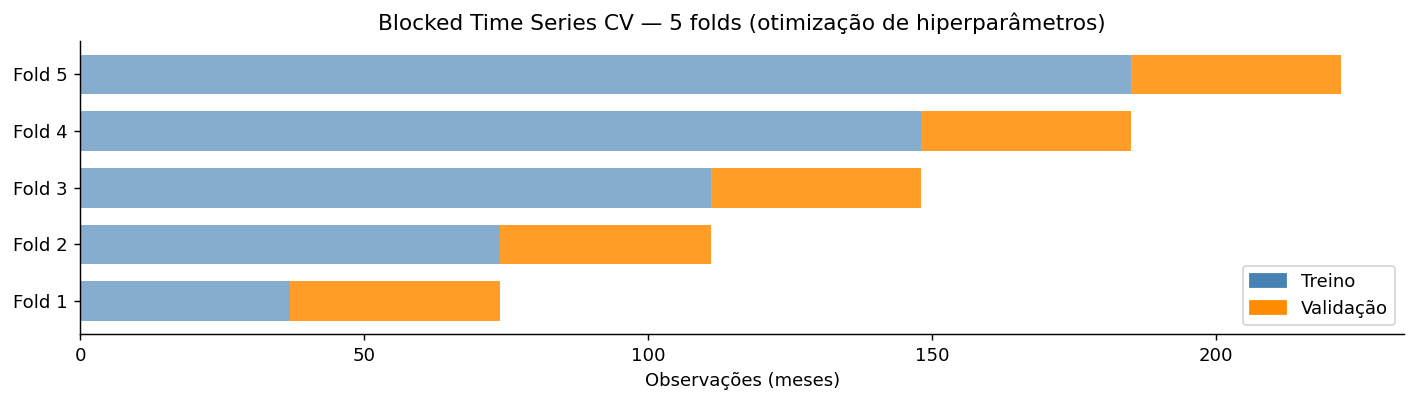

In [11]:
def blocked_ts_split(n, n_splits=5):
    """
    Blocked time series split: n_splits folds consecutivos preservando ordem cronológica.
    """
    fold_size = n // (n_splits + 1)
    splits = []
    for i in range(1, n_splits + 1):
        train_end = i * fold_size
        val_end   = train_end + fold_size
        splits.append((np.arange(0, train_end), np.arange(train_end, val_end)))
    return splits


# Visualização do esquema
fig, ax = plt.subplots(figsize=(11, 3.2))
splits  = blocked_ts_split(len(train_data), n_splits=5)
colors  = ['steelblue', 'darkorange']

for i, (tr_idx, val_idx) in enumerate(splits):
    ax.barh(i, len(tr_idx),  left=0,            color=colors[0], alpha=0.65, height=0.7)
    ax.barh(i, len(val_idx), left=len(tr_idx),  color=colors[1], alpha=0.85, height=0.7)

ax.set_yticks(range(5))
ax.set_yticklabels([f'Fold {i+1}' for i in range(5)])
ax.set_xlabel('Observações (meses)')
ax.set_title('Blocked Time Series CV — 5 folds (otimização de hiperparâmetros)')

from matplotlib.patches import Patch
ax.legend(handles=[
    Patch(color=colors[0], label='Treino'),
    Patch(color=colors[1], label='Validação'),
])
plt.tight_layout()
plt.savefig('lgbm_cv_schema.png', dpi=150, bbox_inches='tight')
plt.show()

## 5. Otimização de hiperparâmetros

Grid search com blocked CV. Métrica de otimização: MAE (mesma da avaliação final).
Early stopping com paciência 50 sobre o último fold de validação.


In [12]:
PARAM_GRID = {
    'learning_rate':  [0.01, 0.05, 0.1],
    'n_estimators':   [100, 200, 300, 500],
    'max_depth':      [3, 5, 7],
    'num_leaves':     [15, 31, 63],
}


def grid_search_lgbm(X, y, param_grid, n_splits=5):
    splits   = blocked_ts_split(len(X), n_splits)
    best_mae = np.inf
    best_params = None
    rows = []

    for params in ParameterGrid(param_grid):
        fold_maes = []
        for tr_idx, val_idx in splits:
            X_tr, y_tr   = X.iloc[tr_idx], y.iloc[tr_idx]
            X_val, y_val = X.iloc[val_idx], y.iloc[val_idx]

            model = lgb.LGBMRegressor(**params, random_state=42, verbose=-1)
            model.fit(
                X_tr, y_tr,
                eval_set=[(X_val, y_val)],
                callbacks=[
                    lgb.early_stopping(stopping_rounds=50, verbose=False),
                    lgb.log_evaluation(period=-1),
                ],
            )
            fold_maes.append(mean_absolute_error(y_val, model.predict(X_val)))

        cv_mae = float(np.mean(fold_maes))
        rows.append({**params, 'cv_mae': cv_mae})

        if cv_mae < best_mae:
            best_mae    = cv_mae
            best_params = params

    return best_params, best_mae, pd.DataFrame(rows).sort_values('cv_mae')


feat_cols_h1 = get_feature_cols(feat_full, horizon=1, baseline_only=False)
X_tr_h1      = train_data[feat_cols_h1]
y_tr_h1      = train_data[TARGET]

print(f'Tuning sobre {len(feat_cols_h1)} features, {len(X_tr_h1)} obs de treino.')
print('Rodando grid search...')
best_params, best_cv_mae, grid_results = grid_search_lgbm(X_tr_h1, y_tr_h1, PARAM_GRID)

print(f'\nMelhores hiperparâmetros: {best_params}')
print(f'CV MAE: {best_cv_mae:.4f}')
print('\nTop 5:')
print(grid_results.head(5).round(4).to_string(index=False))

Tuning sobre 17 features, 226 obs de treino.
Rodando grid search...

Melhores hiperparâmetros: {'learning_rate': 0.05, 'max_depth': 7, 'n_estimators': 200, 'num_leaves': 15}
CV MAE: 0.2165

Top 5:
 learning_rate  max_depth  n_estimators  num_leaves  cv_mae
          0.05          7           300          31  0.2165
          0.05          7           200          15  0.2165
          0.05          7           200          31  0.2165
          0.05          7           200          63  0.2165
          0.05          7           300          15  0.2165


## 6. Avaliação fora da amostra — expanding window (h = 1, 2, 3)

Três especificações para isolar contribuições:

| Especificação    | Features incluídas                                          | Propósito               |
|------------------|-------------------------------------------------------------|-------------------------|
| `M0_baseline_fx` | apenas `usd_brl_lag4`                                       | Mesmo conjunto de M1 do ARIMAX |
| `M0_baseline`    | `usd_brl_lag4` + `us_cpi_lag2/3`                            | Mesmo conjunto de M2 do ARIMAX |
| `M1_fx`          | conjunto completo SEM CPI                                   | Câmbio + features extras |
| `M2_fx_cpi`      | conjunto completo COM CPI                                   | Spec principal LightGBM |

A comparação **M0_baseline vs. M1/M2** isola o ganho da engenharia de features.
A comparação **M1_fx vs. M2_fx_cpi** testa H3 com a estrutura completa.


In [13]:
def mase(actual, predicted, train_actual):
    naive_mae = np.mean(np.abs(np.diff(train_actual)))
    return np.mean(np.abs(actual - predicted)) / naive_mae


def expanding_window_lgbm(data, feat_cols, target, horizon, params,
                           train_end=TRAIN_END, min_train=36):
    test_idx = data[data.index > train_end].index
    preds, actuals, dates = [], [], []

    for t in test_idx:
        cutoff  = t - pd.DateOffset(months=horizon)
        train_w = data[data.index <= cutoff]

        if len(train_w) < min_train:
            continue

        X_tr = train_w[feat_cols]
        y_tr = train_w[target]
        X_te = data.loc[[t], feat_cols]

        model = lgb.LGBMRegressor(**params, random_state=42, verbose=-1)
        model.fit(X_tr, y_tr)

        preds.append(float(model.predict(X_te)[0]))
        actuals.append(float(data.loc[t, target]))
        dates.append(t)

    return np.array(actuals), np.array(preds), pd.DatetimeIndex(dates)


def remove_cpi_cols(cols):
    return [c for c in cols if 'us_cpi' not in c]


results_ew = {}
print('Iniciando expanding window LightGBM...')

for h in [1, 2, 3]:
    feat_full_h     = get_feature_cols(feat_full, h, baseline_only=False)
    feat_baseline_h = get_feature_cols(feat_full, h, baseline_only=True)
    feat_full_fx    = remove_cpi_cols(feat_full_h)
    feat_base_fx    = remove_cpi_cols(feat_baseline_h)

    specs = [
        ('M0_baseline_fx',  feat_base_fx),
        ('M0_baseline',     feat_baseline_h),
        ('M1_fx',           feat_full_fx),
        ('M2_fx_cpi',       feat_full_h),
    ]

    for name, cols in specs:
        if not cols:
            continue
        act, pred, dates = expanding_window_lgbm(data, cols, TARGET, h, best_params)
        results_ew[(name, h)] = {
            'actuals': act,
            'preds':   pred,
            'dates':   dates,
            'features': cols,
        }
        print(f'  h={h} | {name:18} ({len(cols):2} feats) ✓  ({(~np.isnan(pred)).sum()} previsões)')

print('Expanding window concluída.')

Iniciando expanding window LightGBM...
  h=1 | M0_baseline_fx     ( 1 feats) ✓  (60 previsões)
  h=1 | M0_baseline        ( 3 feats) ✓  (60 previsões)
  h=1 | M1_fx              (13 feats) ✓  (60 previsões)
  h=1 | M2_fx_cpi          (17 feats) ✓  (60 previsões)
  h=2 | M0_baseline_fx     ( 1 feats) ✓  (60 previsões)
  h=2 | M0_baseline        ( 3 feats) ✓  (60 previsões)
  h=2 | M1_fx              (12 feats) ✓  (60 previsões)
  h=2 | M2_fx_cpi          (16 feats) ✓  (60 previsões)
  h=3 | M0_baseline_fx     ( 1 feats) ✓  (60 previsões)
  h=3 | M0_baseline        ( 2 feats) ✓  (60 previsões)
  h=3 | M1_fx              (11 feats) ✓  (60 previsões)
  h=3 | M2_fx_cpi          (14 feats) ✓  (60 previsões)
Expanding window concluída.


## 7. Métricas — período completo e por subperíodo

In [14]:
train_ipca = data[data.index <= TRAIN_END][TARGET].values

rows = []
for (name, h), d in results_ew.items():
    act, pred = d['actuals'], d['preds']
    mask = ~np.isnan(pred)
    rows.append({
        'model':   name,
        'horizon': h,
        'MAE':     mean_absolute_error(act[mask], pred[mask]),
        'RMSE':    np.sqrt(mean_squared_error(act[mask], pred[mask])),
        'MASE':    mase(act[mask], pred[mask], train_ipca),
        'n':       int(mask.sum()),
    })

metrics_df = pd.DataFrame(rows).sort_values(['horizon', 'MAE'])
print('Métricas LightGBM — período completo (jan/2020–dez/2024):')
print(metrics_df.round(4).to_string(index=False))

Métricas LightGBM — período completo (jan/2020–dez/2024):
         model  horizon    MAE   RMSE   MASE  n
     M2_fx_cpi        1 0.3118 0.4106 1.3808 60
         M1_fx        1 0.3142 0.4097 1.3913 60
M0_baseline_fx        1 0.3548 0.4579 1.5712 60
   M0_baseline        1 0.3692 0.4635 1.6347 60
         M1_fx        2 0.3029 0.3948 1.3414 60
     M2_fx_cpi        2 0.3079 0.4084 1.3633 60
M0_baseline_fx        2 0.3583 0.4574 1.5866 60
   M0_baseline        2 0.3717 0.4619 1.6461 60
     M2_fx_cpi        3 0.3168 0.4106 1.4030 60
         M1_fx        3 0.3193 0.4086 1.4141 60
M0_baseline_fx        3 0.3601 0.4626 1.5947 60
   M0_baseline        3 0.3683 0.4650 1.6311 60


In [15]:
rows_sub = []
for (name, h), d in results_ew.items():
    mask_v = ~np.isnan(d['preds'])
    dates  = d['dates'][mask_v]
    act_v  = d['actuals'][mask_v]
    pred_v = d['preds'][mask_v]

    for label, start, end in [
        ('choque_2020_2021',  '2020-01-01', '2021-12-31'),
        ('acomodacao_22_24',  '2022-01-01', '2024-12-31'),
    ]:
        m_sub = (dates >= start) & (dates <= end)
        if m_sub.sum() < 3:
            continue
        rows_sub.append({
            'model':     name,
            'horizon':   h,
            'subperiod': label,
            'MAE':       mean_absolute_error(act_v[m_sub], pred_v[m_sub]),
            'RMSE':      np.sqrt(mean_squared_error(act_v[m_sub], pred_v[m_sub])),
            'n':         int(m_sub.sum()),
        })

subperiod_df = pd.DataFrame(rows_sub).sort_values(['horizon', 'subperiod', 'MAE'])
print('Métricas por subperíodo:')
print(subperiod_df.round(4).to_string(index=False))

Métricas por subperíodo:
         model  horizon        subperiod    MAE   RMSE  n
         M1_fx        1 acomodacao_22_24 0.2863 0.3893 36
     M2_fx_cpi        1 acomodacao_22_24 0.2864 0.3947 36
M0_baseline_fx        1 acomodacao_22_24 0.3031 0.4261 36
   M0_baseline        1 acomodacao_22_24 0.3431 0.4510 36
     M2_fx_cpi        1 choque_2020_2021 0.3499 0.4332 24
         M1_fx        1 choque_2020_2021 0.3560 0.4387 24
   M0_baseline        1 choque_2020_2021 0.4082 0.4817 24
M0_baseline_fx        1 choque_2020_2021 0.4324 0.5018 24
         M1_fx        2 acomodacao_22_24 0.2697 0.3663 36
     M2_fx_cpi        2 acomodacao_22_24 0.2718 0.3814 36
M0_baseline_fx        2 acomodacao_22_24 0.3099 0.4291 36
   M0_baseline        2 acomodacao_22_24 0.3497 0.4540 36
         M1_fx        2 choque_2020_2021 0.3527 0.4341 24
     M2_fx_cpi        2 choque_2020_2021 0.3619 0.4459 24
   M0_baseline        2 choque_2020_2021 0.4047 0.4736 24
M0_baseline_fx        2 choque_2020_2021 0.4309

## 8. Importância de variáveis (gain)

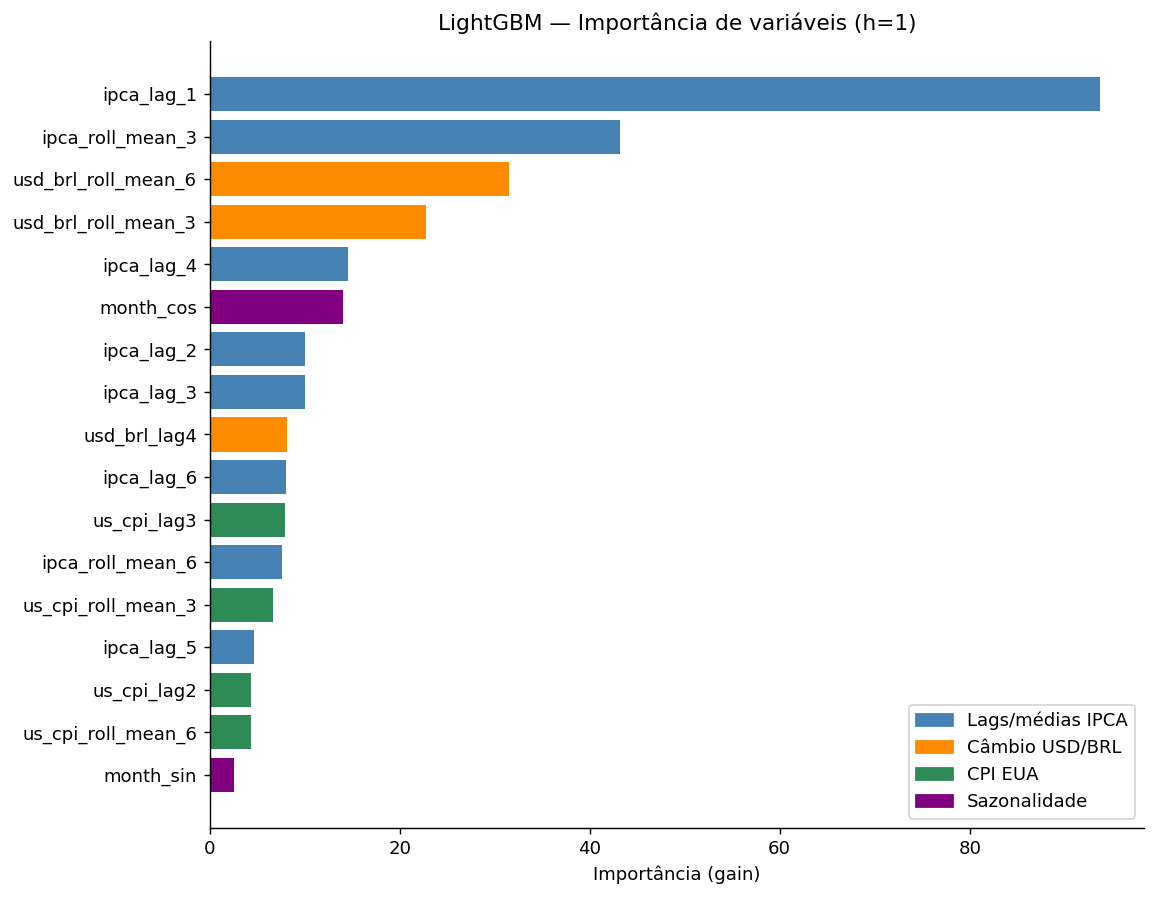


Importância das variáveis de CPI (gain):
           feature  importance_gain
       us_cpi_lag3         7.879889
us_cpi_roll_mean_3         6.717376
       us_cpi_lag2         4.402637
us_cpi_roll_mean_6         4.367811


In [16]:
feat_cols_h1 = get_feature_cols(feat_full, horizon=1, baseline_only=False)

model_final = lgb.LGBMRegressor(**best_params, random_state=42, verbose=-1)
model_final.fit(train_data[feat_cols_h1], train_data[TARGET])

# gain importance (mais informativa que split)
gain_importance = model_final.booster_.feature_importance(importance_type='gain')

importance_df = pd.DataFrame({
    'feature':    feat_cols_h1,
    'importance_gain': gain_importance,
}).sort_values('importance_gain', ascending=False)

# Visualização
fig, ax = plt.subplots(figsize=(9, 7))
colors = []
for f in importance_df['feature']:
    if 'cpi' in f:
        colors.append('seagreen')
    elif 'brl' in f:
        colors.append('darkorange')
    elif 'month' in f:
        colors.append('purple')
    else:
        colors.append('steelblue')

ax.barh(importance_df['feature'], importance_df['importance_gain'], color=colors)
ax.set_xlabel('Importância (gain)')
ax.set_title('LightGBM — Importância de variáveis (h=1)')
ax.invert_yaxis()

from matplotlib.patches import Patch
ax.legend(handles=[
    Patch(color='steelblue',  label='Lags/médias IPCA'),
    Patch(color='darkorange', label='Câmbio USD/BRL'),
    Patch(color='seagreen',   label='CPI EUA'),
    Patch(color='purple',     label='Sazonalidade'),
])

plt.tight_layout()
plt.savefig('lgbm_feature_importance.png', dpi=150, bbox_inches='tight')
plt.show()

print('\nImportância das variáveis de CPI (gain):')
print(importance_df[importance_df['feature'].str.contains('cpi')].to_string(index=False))

## 9. Análise por regime de volatilidade cambial (H2)

In [17]:
df_raw['vol_cambio_12m'] = df_raw['usd_brl_pct'].rolling(12).std()
vol_threshold            = df_raw[df_raw.index <= TRAIN_END]['vol_cambio_12m'].median()
df_raw['regime_vol']     = np.where(df_raw['vol_cambio_12m'] > vol_threshold, 'alta', 'baixa')

print(f'Limiar de volatilidade (mediana treino): {vol_threshold:.4f}')
print(f'\nDistribuição no teste:')
print(df_raw[df_raw.index > TRAIN_END]['regime_vol'].value_counts())

Limiar de volatilidade (mediana treino): 4.0499

Distribuição no teste:
regime_vol
alta     33
baixa    27
Name: count, dtype: int64


In [18]:
rows_regime = []
for (name, h), d in results_ew.items():
    mask_v = ~np.isnan(d['preds'])
    dates  = d['dates'][mask_v]
    act_v  = d['actuals'][mask_v]
    pred_v = d['preds'][mask_v]

    regimes = df_raw.loc[dates, 'regime_vol'].values

    for regime in ['alta', 'baixa']:
        m_reg = regimes == regime
        if m_reg.sum() < 3:
            continue
        rows_regime.append({
            'model':   name,
            'horizon': h,
            'regime':  regime,
            'MAE':     mean_absolute_error(act_v[m_reg], pred_v[m_reg]),
            'RMSE':    np.sqrt(mean_squared_error(act_v[m_reg], pred_v[m_reg])),
            'n':       int(m_reg.sum()),
        })

regime_df = pd.DataFrame(rows_regime).sort_values(['horizon', 'regime', 'MAE'])
print('Métricas por regime:')
print(regime_df.round(4).to_string(index=False))

Métricas por regime:
         model  horizon regime    MAE   RMSE  n
     M2_fx_cpi        1   alta 0.3577 0.4585 33
         M1_fx        1   alta 0.3738 0.4720 33
   M0_baseline        1   alta 0.4234 0.5124 33
M0_baseline_fx        1   alta 0.4299 0.5247 33
         M1_fx        1  baixa 0.2413 0.3175 27
     M2_fx_cpi        1  baixa 0.2557 0.3429 27
M0_baseline_fx        1  baixa 0.2630 0.3597 27
   M0_baseline        1  baixa 0.3028 0.3957 27
     M2_fx_cpi        2   alta 0.3607 0.4588 33
         M1_fx        2   alta 0.3675 0.4525 33
   M0_baseline        2   alta 0.4257 0.5091 33
M0_baseline_fx        2   alta 0.4333 0.5232 33
         M1_fx        2  baixa 0.2240 0.3100 27
     M2_fx_cpi        2  baixa 0.2433 0.3367 27
M0_baseline_fx        2  baixa 0.2666 0.3609 27
   M0_baseline        2  baixa 0.3058 0.3967 27
     M2_fx_cpi        3   alta 0.3850 0.4705 33
         M1_fx        3   alta 0.3878 0.4654 33
M0_baseline_fx        3   alta 0.4364 0.5298 33
   M0_baseline     

## 10. Teste de Diebold-Mariano (H3)

In [19]:
def diebold_mariano(e1, e2, h=1):
    d      = e1**2 - e2**2
    n      = len(d)
    d_mean = np.mean(d)

    gamma0 = np.var(d, ddof=1)
    gammas = [np.cov(d[k:], d[:-k])[0, 1] for k in range(1, h)] if h > 1 else []
    var_d  = max((gamma0 + 2 * sum(gammas)) / n, 1e-10)

    dm_stat = d_mean / np.sqrt(var_d)
    p_value = 2 * (1 - stats.norm.cdf(abs(dm_stat)))
    return {'dm_stat': dm_stat, 'p_value': p_value}


print('Teste DM — H3: ganho do CPI sobre câmbio isolado')
print('DM < 0 → spec com CPI melhor | p < 0.05 → rejeita H0 (acurácia equivalente)')
print('-' * 80)

dm_rows = []
for h in [1, 2, 3]:
    for spec_base, spec_cpi in [
        ('M0_baseline_fx', 'M0_baseline'),  # baseline puro (sem features extras)
        ('M1_fx',          'M2_fx_cpi'),    # spec completo
    ]:
        m1_d = results_ew.get((spec_base, h))
        m2_d = results_ew.get((spec_cpi,  h))
        if not m1_d or not m2_d:
            continue

        act  = m1_d['actuals']
        e1   = act - m1_d['preds']
        e2   = act - m2_d['preds']
        mask = ~(np.isnan(e1) | np.isnan(e2))

        dm   = diebold_mariano(e1[mask], e2[mask], h=h)
        sig  = '✓ SIGNIFICATIVO (5%)' if dm['p_value'] < 0.05 else '✗ não significativo'
        print(f'  h={h} | {spec_base} vs {spec_cpi}: DM={dm["dm_stat"]:+.4f}, p={dm["p_value"]:.4f}  → {sig}')

        dm_rows.append({
            'horizon':         h,
            'spec_base':       spec_base,
            'spec_cpi':        spec_cpi,
            'dm_stat':         dm['dm_stat'],
            'p_value':         dm['p_value'],
            'significant_5pct': dm['p_value'] < 0.05,
        })

dm_df = pd.DataFrame(dm_rows)

Teste DM — H3: ganho do CPI sobre câmbio isolado
DM < 0 → spec com CPI melhor | p < 0.05 → rejeita H0 (acurácia equivalente)
--------------------------------------------------------------------------------
  h=1 | M0_baseline_fx vs M0_baseline: DM=-0.3509, p=0.7257  → ✗ não significativo
  h=1 | M1_fx vs M2_fx_cpi: DM=-0.1121, p=0.9108  → ✗ não significativo
  h=2 | M0_baseline_fx vs M0_baseline: DM=-0.2253, p=0.8218  → ✗ não significativo
  h=2 | M1_fx vs M2_fx_cpi: DM=-1.5199, p=0.1285  → ✗ não significativo
  h=3 | M0_baseline_fx vs M0_baseline: DM=-0.1514, p=0.8797  → ✗ não significativo
  h=3 | M1_fx vs M2_fx_cpi: DM=-0.2292, p=0.8187  → ✗ não significativo


## 11. Visualizações — observado vs. previsto

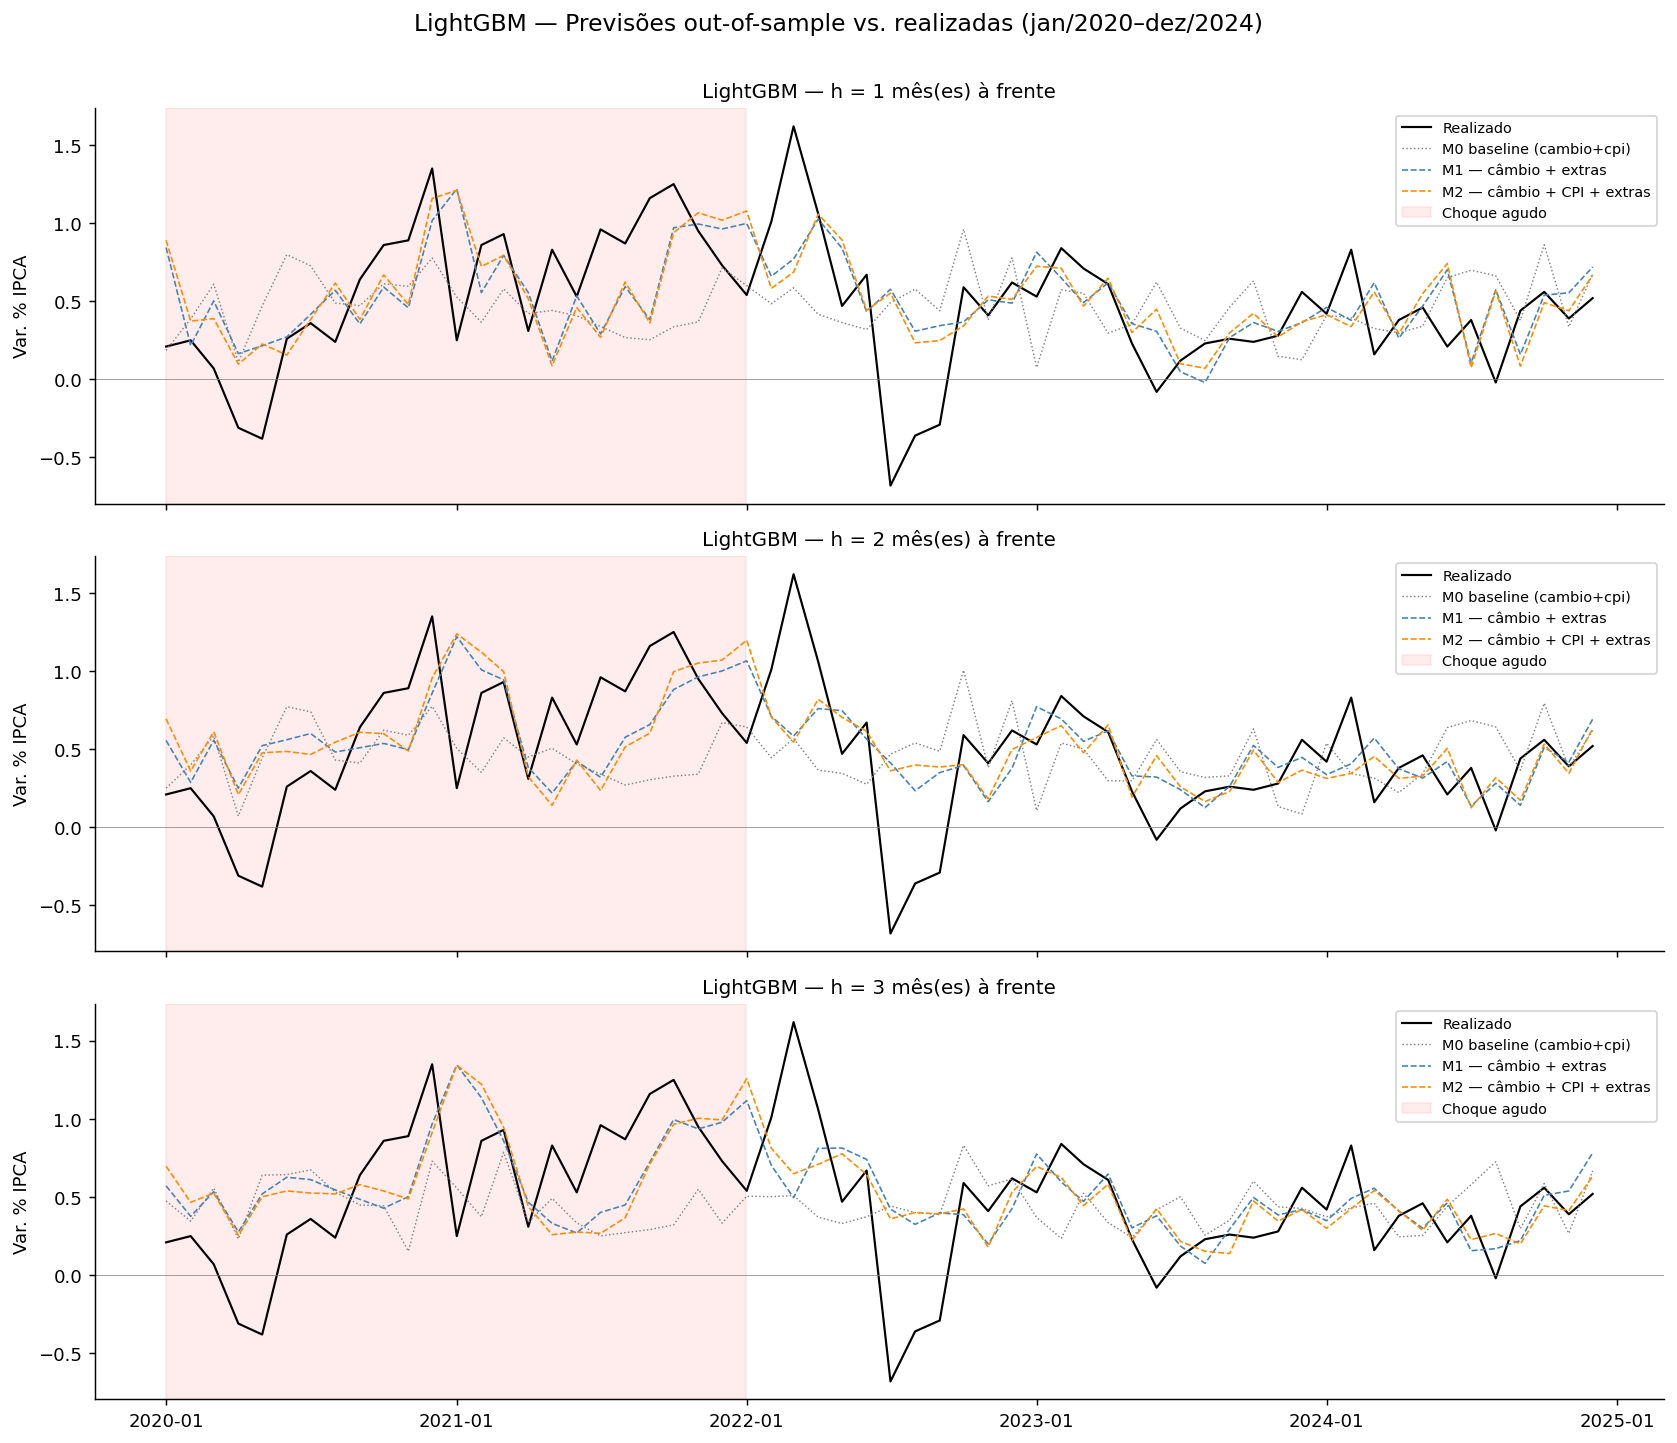

In [20]:
fig, axes = plt.subplots(3, 1, figsize=(13, 11), sharex=True)

for i, h in enumerate([1, 2, 3]):
    ax     = axes[i]
    d_base = results_ew[('M0_baseline', h)]
    d_m1   = results_ew[('M1_fx', h)]
    d_m2   = results_ew[('M2_fx_cpi', h)]

    ax.plot(d_m2['dates'], d_m2['actuals'], color='black',     linewidth=1.2, label='Realizado')
    ax.plot(d_base['dates'], d_base['preds'], color='gray',     linewidth=0.8,
            linestyle=':',  label='M0 baseline (cambio+cpi)')
    ax.plot(d_m1['dates'], d_m1['preds'],   color='steelblue', linewidth=0.9,
            linestyle='--', label='M1 — câmbio + extras')
    ax.plot(d_m2['dates'], d_m2['preds'],   color='darkorange', linewidth=0.9,
            linestyle='--', label='M2 — câmbio + CPI + extras')
    ax.axvspan(pd.Timestamp('2020-01-01'), pd.Timestamp('2021-12-31'),
               alpha=0.07, color='red', label='Choque agudo')
    ax.axhline(0, color='gray', linewidth=0.4)
    ax.set_title(f'LightGBM — h = {h} mês(es) à frente', fontsize=11)
    ax.set_ylabel('Var. % IPCA')
    ax.legend(fontsize=8, loc='upper right')

axes[-1].xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m'))
fig.suptitle('LightGBM — Previsões out-of-sample vs. realizadas (jan/2020–dez/2024)',
             fontsize=13, y=1.005)
plt.tight_layout()
plt.savefig('lgbm_ew_forecasts.png', dpi=150, bbox_inches='tight')
plt.show()

## 12. Exportação

In [21]:
with open('lgbm_best_params.pkl', 'wb') as f: pickle.dump(best_params,  f)
with open('lgbm_model_final.pkl', 'wb') as f: pickle.dump(model_final,  f)
with open('lgbm_grid_results.pkl', 'wb') as f: pickle.dump(grid_results, f)

metrics_df.to_csv('lgbm_metrics.csv',           index=False)
subperiod_df.to_csv('lgbm_metrics_subperiod.csv', index=False)
regime_df.to_csv('lgbm_metrics_regime.csv',     index=False)
dm_df.to_csv('lgbm_dm_test.csv',                index=False)
importance_df.to_csv('lgbm_feature_importance.csv', index=False)

for (name, h), d in results_ew.items():
    pd.DataFrame({
        'date':      d['dates'],
        'actual':    d['actuals'],
        'predicted': d['preds'],
    }).to_csv(f'lgbm_preds_{name}_h{h}.csv', index=False)

print('Exportação concluída.')

Exportação concluída.
